# Discriminative Audio Models: from Sound Classification to Speech Recognition

**Black Sea AI lecture**

The lecture covers *discriminative* audio tasks: we observe an audio signal $x$ and want to model $p(y \mid x)$.

| Task | Input | Target $y$ | Granularity |
|---|---|---|---|
| Sound event classification | 5 sec clip | one of 50 classes | **one label per clip** |
| Automatic Speech Recognition (ASR) | utterance | sequence of characters / tokens | **sequence of labels**, length unknown in advance |

Both tasks share the same skeleton:

$$\text{waveform} \;\rightarrow\; \text{features (spectrogram / learned)} \;\rightarrow\; \text{encoder} \;\rightarrow\; \text{head} \;\rightarrow\; \text{loss}$$

The difference is in the head and the loss. We will build the classification pipeline from scratch, then see what changes when the output becomes a sequence (CTC and sequence-to-sequence).

# Agenda

1. [Part 1. Audio Classification](#Part1)
    1. [Data and validation split](#Data)
    2. [Dataset and augmentations](#Dataset)
    3. [Model: spectrogram + CNN](#Model)
    4. [Training with cross-validation](#Training)
    5. [Evaluation and error analysis](#Evaluation)
2. [From clip labels to label sequences](#Bridge)
3. [Part 2. Automatic Speech Recognition](#Part2)
    1. [Task and data](#ASR-Data)
    2. [Metrics: WER and CER](#ASR-Metrics)
    3. [CTC approach (w2v-BERT 2.0)](#ASR-CTC)
    4. [Sequence-to-sequence approach (Whisper)](#ASR-Seq2Seq)
    5. [CTC vs Seq2Seq comparison](#ASR-Comparison)
4. [Takeaways](#Takeaways)

In [1]:
import os
# Pick the GPU before importing torch
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

import math
import re
import time
import unicodedata
from glob import glob

import IPython.display as ipd
import jiwer
import jsonlines
import librosa
import lightning
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
import timm
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchmetrics
from audiomentations import AddGaussianNoise, Compose, TimeStretch
from lightning.pytorch.callbacks import ModelCheckpoint
from lightning.pytorch.loggers import CSVLogger
from sklearn.model_selection import StratifiedGroupKFold
from torchaudio.functional import amplitude_to_DB
from torchaudio.transforms import FrequencyMasking, MelSpectrogram, TimeMasking
from tqdm.auto import tqdm

%matplotlib inline

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
# The GPU may be shared with other jobs: cap the memory this notebook may take
if DEVICE == "cuda":
    torch.cuda.set_per_process_memory_fraction(0.6)
    torch.set_float32_matmul_precision("high")
    print(torch.cuda.get_device_name(0))

NVIDIA GeForce RTX 5090


<a id='Part1'></a>
# Part 1. Audio Classification

<a id='Data'></a>
## Data and validation split

We use [ESC-50](https://github.com/karolpiczak/ESC-50): 2000 environmental recordings, 5 seconds each, 50 classes (dog, rain, chainsaw, crying baby, ...), 40 clips per class.

In [2]:
# # Uncomment to download (~600MB)
# !mkdir -p ../data/esc50 && cd ../data/esc50 && curl -L -o esc50.zip https://github.com/karoldvl/ESC-50/archive/master.zip && unzip -q esc50.zip && rm esc50.zip

ESC50_ROOT = "../data/esc50/ESC-50-master/"

In [3]:
meta_df = pd.read_csv(os.path.join(ESC50_ROOT, "meta/esc50.csv"))
meta_df["filepath"] = ESC50_ROOT + "audio/" + meta_df["filename"]
assert meta_df["filepath"].apply(os.path.exists).all()

class_idx2name = meta_df.drop_duplicates("target").set_index("target")["category"].sort_index().to_dict()
N_CLASSES = len(class_idx2name)

print("Clips:", len(meta_df), "| classes:", N_CLASSES, "| clips per class:", meta_df["target"].value_counts().unique())
meta_df.head()

Clips: 2000 | classes: 50 | clips per class: [40]


,filename,fold,target,category,esc10,src_file,take,filepath
0,1-100032-A-0.wav,1,0,dog,True,100032,A,../data/esc50/ESC-50-master/audio/1-100032-A-0...
1,1-100038-A-14.wav,1,14,chirping_birds,False,100038,A,../data/esc50/ESC-50-master/audio/1-100038-A-1...
2,1-100210-A-36.wav,1,36,vacuum_cleaner,False,100210,A,../data/esc50/ESC-50-master/audio/1-100210-A-3...
3,1-100210-B-36.wav,1,36,vacuum_cleaner,False,100210,B,../data/esc50/ESC-50-master/audio/1-100210-B-3...
4,1-101296-A-19.wav,1,19,thunderstorm,False,101296,A,../data/esc50/ESC-50-master/audio/1-101296-A-1...


Always check the audio itself: sample rate, duration and number of channels define the whole preprocessing.

In [4]:
audio_info = pd.DataFrame([sf.info(p).__dict__ for p in meta_df["filepath"]])
audio_info[["samplerate", "channels", "duration", "subtype"]].value_counts()

samplerate  channels  duration  subtype
44100       1         5.0       PCM_16     2000
Name: count, dtype: int64

### Hidden leakage: `src_file`

Several clips were cut from **the same original recording** (`src_file`). Two clips of the same washing machine in train and validation make the score look much better than it is.

The split has to be **grouped** by `src_file` and **stratified** by class.

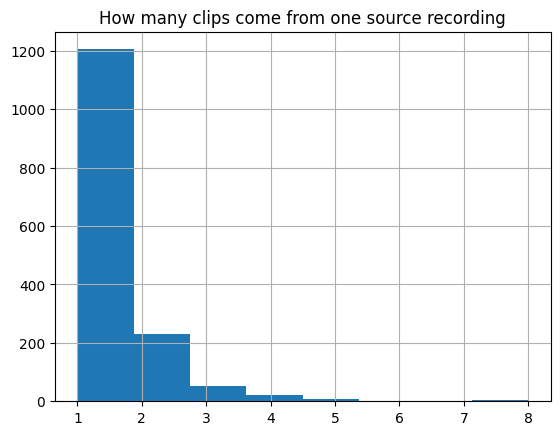

In [5]:
plt.title("How many clips come from one source recording")
meta_df["src_file"].value_counts().hist(bins=8)
plt.show()

In [6]:
# 10% hold-out test set, the rest is split into 5 cross-validation folds
splitter = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=42)
_, test_idx = next(splitter.split(meta_df, meta_df["target"], meta_df["src_file"]))
test_df = meta_df.iloc[test_idx].reset_index(drop=True)
train_df = meta_df.drop(index=test_idx).reset_index(drop=True)

train_df["fold"] = -1
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
for fold_id, (_, val_idx) in enumerate(splitter.split(train_df, train_df["target"], train_df["src_file"])):
    train_df.loc[val_idx, "fold"] = fold_id

# Sanity checks: no recording is shared between train/test or between folds
assert not set(train_df["src_file"]) & set(test_df["src_file"])
for fold_id in range(5):
    is_val = train_df["fold"] == fold_id
    assert not set(train_df.loc[is_val, "src_file"]) & set(train_df.loc[~is_val, "src_file"])

print("Train:", len(train_df), "| Test:", len(test_df))
train_df["fold"].value_counts().sort_index()

Train: 1816 | Test: 184


fold
0    374
1    359
2    357
3    354
4    372
Name: count, dtype: int64

### Listen and look

In [7]:
def plot_examples(waveforms, sample_rate, titles, specs=None, num_cols=4, play=True):
    """Spectrogram (top) and waveform (bottom) for every example."""
    num_rows = math.ceil(len(waveforms) / num_cols)
    fig, axs = plt.subplots(2 * num_rows, num_cols, figsize=(num_cols * 3, num_rows * 4), squeeze=False)
    for ax in axs.flat:
        ax.set_axis_off()
    for idx, (wave, title) in enumerate(zip(waveforms, titles)):
        i, j = 2 * (idx // num_cols), idx % num_cols
        if specs is None:
            spec = librosa.power_to_db(librosa.feature.melspectrogram(y=np.asarray(wave), sr=sample_rate, n_mels=128))
        else:
            spec = np.asarray(specs[idx])
        axs[i][j].imshow(spec, origin="lower", aspect="auto")
        axs[i][j].set_title(title, fontsize=10)
        axs[i + 1][j].plot(np.asarray(wave), linewidth=0.5)
    plt.tight_layout()
    plt.show()
    if play:
        for wave, title in zip(waveforms, titles):
            print(title)
            ipd.display(ipd.Audio(np.asarray(wave), rate=sample_rate))

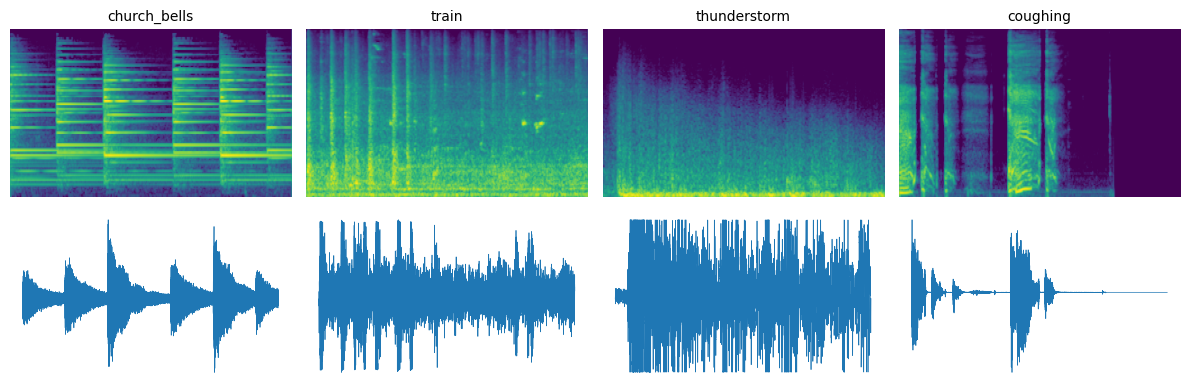

church_bells


train


thunderstorm


coughing


In [8]:
SAMPLE_RATE = 32_000

examples = train_df.sample(4, random_state=1)
plot_examples(
    [librosa.load(p, sr=SAMPLE_RATE)[0] for p in examples["filepath"]],
    SAMPLE_RATE,
    examples["category"].to_list(),
)

<a id='Dataset'></a>
## Dataset and augmentations

The dataset returns raw waveforms. The spectrogram is computed **inside the model** on GPU: it is fast and it guarantees that training and inference use exactly the same features.

Waveform augmentations are applied on CPU with [audiomentations](https://github.com/iver56/audiomentations).

In [9]:
class AudioDataset(torch.utils.data.Dataset):
    def __init__(self, df, sample_rate=SAMPLE_RATE, duration_sec=5, audio_transforms=None):
        self.filepaths = df["filepath"].to_list()
        self.targets = df["target"].to_list()
        self.sample_rate = sample_rate
        self.n_samples = sample_rate * duration_sec
        self.audio_transforms = audio_transforms

    def __len__(self):
        return len(self.filepaths)

    def __getitem__(self, idx):
        au, _ = librosa.load(self.filepaths[idx], sr=self.sample_rate)
        if self.audio_transforms is not None:
            au = self.audio_transforms(samples=au, sample_rate=self.sample_rate)
        # TimeStretch changes the length: crop / pad back to a fixed size
        au = librosa.util.fix_length(au, size=self.n_samples)
        au = librosa.util.normalize(au)
        return torch.from_numpy(au).float(), self.targets[idx]


train_augs = Compose([
    AddGaussianNoise(min_amplitude=0.005, max_amplitude=0.01, p=0.5),
    TimeStretch(min_rate=0.8, max_rate=1.2, p=0.5),
])

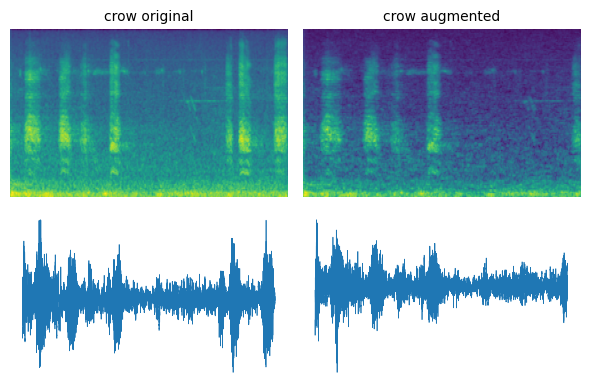

crow original


crow augmented


In [10]:
idx = 7
au, target = AudioDataset(train_df)[idx]
au_aug, _ = AudioDataset(train_df, audio_transforms=Compose([
    AddGaussianNoise(min_amplitude=0.005, max_amplitude=0.01, p=1.0),
    TimeStretch(min_rate=0.8, max_rate=0.8, p=1.0),
]))[idx]

plot_examples([au, au_aug], SAMPLE_RATE, [class_idx2name[target] + " original", class_idx2name[target] + " augmented"], num_cols=2)

> **TODO**: implement [MixUp](https://arxiv.org/abs/1710.09412) - one of the strongest augmentations for audio classification.

<a id='Model'></a>
## Model: spectrogram + CNN

1. Mel spectrogram and log (dB) scale.
2. Per-sample normalization.
3. SpecAugment (only in training): mask random frequency bands and time segments.
4. CNN encoder: an ImageNet-pretrained [EfficientNet](https://arxiv.org/abs/1905.11946) from [timm](https://github.com/huggingface/pytorch-image-models). A spectrogram is a 1-channel "image".
5. Pooling over frequency and time, then a linear classifier.

The architecture is close to the one used on [BirdCLEF 2023](https://www.kaggle.com/competitions/birdclef-2023/discussion/412808):

![nn_arch](images/audio_nn_arch.png)

In [11]:
class LogMelSpectrogram(nn.Module):
    def __init__(self, top_db=80.0, eps=1e-6, **mel_params):
        super().__init__()
        self.mel = MelSpectrogram(**mel_params)
        self.top_db = top_db
        self.eps = eps

    def forward(self, x):  # (B, samples) -> (B, n_mels, frames)
        spec = self.mel(x)
        # The channel dim makes top_db clipping per sample, not per batch
        spec = amplitude_to_DB(spec.unsqueeze(1), multiplier=10.0, amin=1e-10, db_multiplier=0.0, top_db=self.top_db).squeeze(1)
        # Standardize and scale each spectrogram to [0, 1]
        spec = (spec - spec.mean((-2, -1), keepdim=True)) / (spec.std((-2, -1), keepdim=True) + self.eps)
        spec_min, spec_max = spec.amin((-2, -1), keepdim=True), spec.amax((-2, -1), keepdim=True)
        return (spec - spec_min) / (spec_max - spec_min + self.eps)


class SpecAugment(nn.Module):
    def __init__(self, freq_mask=20, time_mask=30, n_masks=3):
        super().__init__()
        # iid_masks=True: a different mask for each sample in the batch
        self.freq = FrequencyMasking(freq_mask, iid_masks=True)
        self.time = TimeMasking(time_mask, iid_masks=True)
        self.n_masks = n_masks

    def forward(self, spec):  # (B, F, T)
        spec = spec.unsqueeze(1)
        for _ in range(self.n_masks):
            spec = self.time(self.freq(spec))
        return spec.squeeze(1)


class SpecCNNClassifier(nn.Module):
    def __init__(self, backbone="tf_efficientnet_b0.in1k", n_classes=N_CLASSES, pretrained=True, dropout=0.5, spec_augment=True):
        super().__init__()
        self.spectrogram = LogMelSpectrogram(sample_rate=SAMPLE_RATE, n_mels=128, f_min=20, n_fft=1024, hop_length=512, normalized=True)
        self.spec_augment = SpecAugment() if spec_augment else None
        self.backbone = timm.create_model(backbone, features_only=True, pretrained=pretrained, in_chans=1)
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(self.backbone.feature_info.channels()[-1], n_classes))

    def forward(self, x, return_spec=False, return_feature_map=False):
        spec = self.spectrogram(x)
        if self.spec_augment is not None and self.training:
            spec = self.spec_augment(spec)
        if return_spec:
            return spec
        feature_map = self.backbone(spec.unsqueeze(1))[-1]  # (B, C, F', T')
        if return_feature_map:
            return feature_map
        emb = feature_map.mean((-2, -1))  # global average pooling
        return self.head(emb)

> **TODO**: replace average pooling with [GeM pooling](https://arxiv.org/abs/1711.02512) or attention pooling.

Let's look at what the model "sees" at every stage.

In [12]:
batch_wave, batch_target = next(iter(torch.utils.data.DataLoader(AudioDataset(train_df), batch_size=4, shuffle=True)))
titles = [class_idx2name[t.item()] for t in batch_target]

demo_model = SpecCNNClassifier()
with torch.no_grad():
    demo_model.eval()
    specs = demo_model(batch_wave, return_spec=True)
    demo_model.train()
    specs_aug = demo_model(batch_wave, return_spec=True)
    demo_model.eval()
    feature_maps = demo_model(batch_wave, return_feature_map=True)

print("Waveform:", tuple(batch_wave.shape), "-> Spectrogram:", tuple(specs.shape), "-> CNN feature map:", tuple(feature_maps.shape))

Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


Waveform: (4, 160000) -> Spectrogram: (4, 128, 313) -> CNN feature map: (4, 320, 4, 10)


Log-mel spectrogram


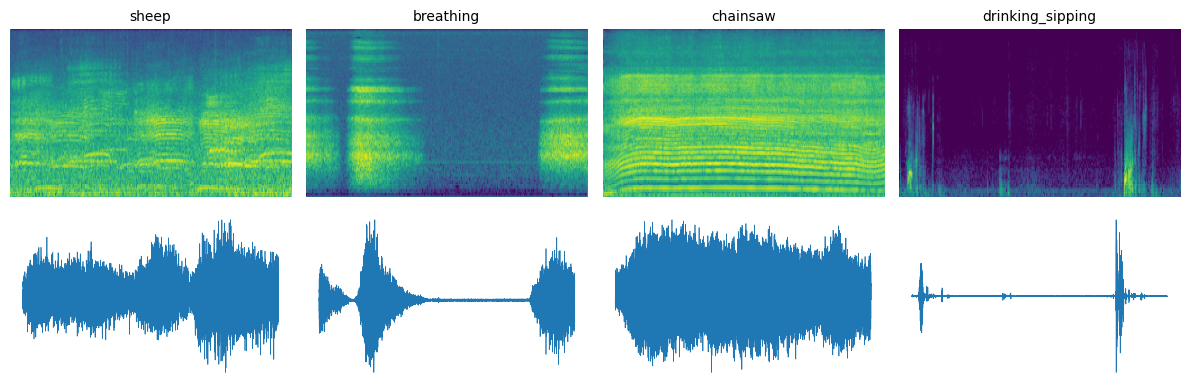

+ SpecAugment


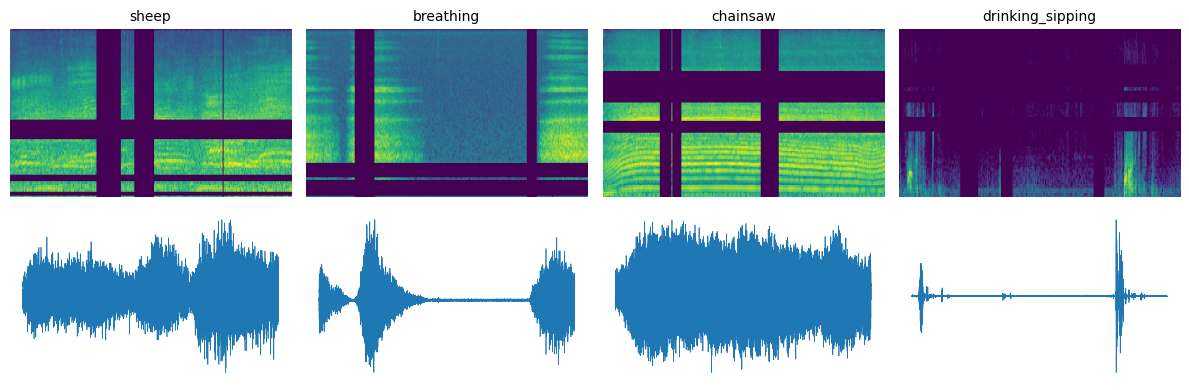

CNN feature map (one channel). Note: the time axis is still there!


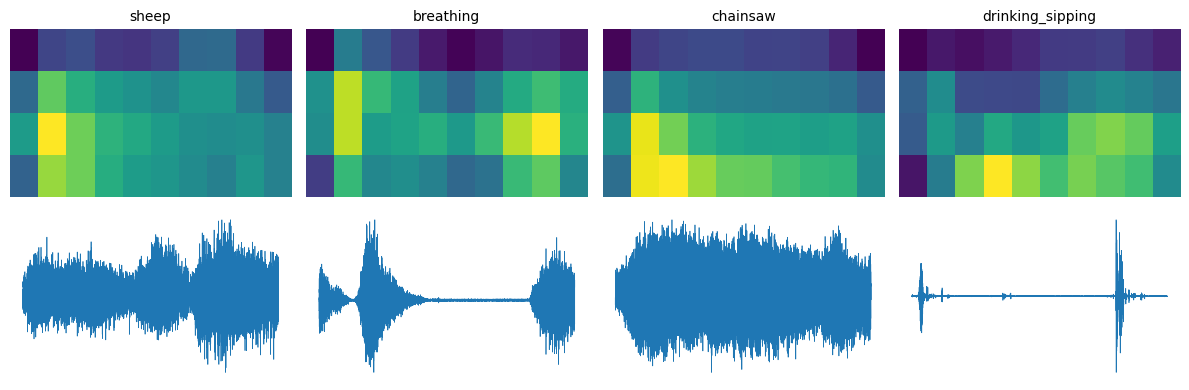

In [13]:
print("Log-mel spectrogram")
plot_examples(batch_wave, SAMPLE_RATE, titles, specs=specs, play=False)
print("+ SpecAugment")
plot_examples(batch_wave, SAMPLE_RATE, titles, specs=specs_aug, play=False)
print("CNN feature map (one channel). Note: the time axis is still there!")
plot_examples(batch_wave, SAMPLE_RATE, titles, specs=feature_maps[:, 0], play=False)

<a id='Training'></a>
## Training with cross-validation

A compact [Lightning](https://lightning.ai/docs/pytorch/stable/) module: cross-entropy loss, Adam, cosine learning-rate schedule, macro F1 as the main metric.

In [15]:
class LitClassifier(lightning.LightningModule):
    def __init__(self, model, lr=1e-3, n_epochs=15, steps_per_epoch=None):
        super().__init__()
        self.model = model
        self.lr, self.n_epochs, self.steps_per_epoch = lr, n_epochs, steps_per_epoch
        self.loss_fn = nn.CrossEntropyLoss()
        self.train_f1 = torchmetrics.F1Score(task="multiclass", num_classes=N_CLASSES, average="macro")
        self.valid_f1 = torchmetrics.F1Score(task="multiclass", num_classes=N_CLASSES, average="macro")

    def training_step(self, batch, batch_idx):
        x, y = batch
        logits = self.model(x)
        loss = self.loss_fn(logits, y)
        self.train_f1.update(logits.argmax(-1), y)
        self.log("train_loss", loss, on_epoch=True, on_step=False, prog_bar=True)
        self.log("train_f1", self.train_f1, on_epoch=True, on_step=False)
        return loss

    def validation_step(self, batch, batch_idx):
        x, y = batch
        logits = self.model(x)
        self.valid_f1.update(logits.argmax(-1), y)
        self.log("valid_loss", self.loss_fn(logits, y), on_epoch=True, prog_bar=True)
        self.log("valid_f1", self.valid_f1, on_epoch=True, prog_bar=True)

    def configure_optimizers(self):
        optimizer = torch.optim.Adam(self.model.parameters(), lr=self.lr)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=self.n_epochs * self.steps_per_epoch, eta_min=1e-6)
        return [optimizer], [{"scheduler": scheduler, "interval": "step"}]


def make_loader(df, train):
    return torch.utils.data.DataLoader(
        AudioDataset(df, audio_transforms=train_augs if train else None),
        batch_size=64, shuffle=train, drop_last=train, num_workers=8, pin_memory=True,
    )


def train_fold(fold_id, n_epochs=15, exp_dir="logdirs/esc50_run2"):
    train_loader = make_loader(train_df[train_df["fold"] != fold_id], train=True)
    valid_loader = make_loader(train_df[train_df["fold"] == fold_id], train=False)
    lit_model = LitClassifier(SpecCNNClassifier(), n_epochs=n_epochs, steps_per_epoch=len(train_loader))
    checkpoint = ModelCheckpoint(monitor="valid_f1", mode="max", save_weights_only=True, filename="{epoch}-{valid_f1:.3f}")
    trainer = lightning.Trainer(
        max_epochs=n_epochs,
        precision="bf16-mixed",
        logger=CSVLogger(exp_dir, name=f"fold_{fold_id}", version=""),
        callbacks=[checkpoint],
        enable_progress_bar=False,
        enable_model_summary=False,
    )
    trainer.fit(lit_model, train_loader, valid_loader)
    print(f"Fold {fold_id}: best valid F1 = {checkpoint.best_model_score:.3f}")
    return checkpoint.best_model_path

**Debug first.** Before running a full cross-validation, make sure that the model can be optimized at all: one fold, a few epochs. If it does not learn even then, train and validate on the same data.

Then train 5 folds. Every fold gives us an out-of-fold (OOF) estimate and a model for the test ensemble.

In [16]:
best_ckpts = [train_fold(fold_id) for fold_id in range(5)]

Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.
Using bfloat16 Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/home/vsydorskyi/src/ucu_audio_processing_course/.venv/lib/python3.11/site-packages/lightning/pytorch/loops/fit_loop.py:317: The number of training batches (22) is smaller than the logging interval Trainer(log_every_n_steps=50). Set a lower value for log_every_n_steps if you want to see logs for the training epoch.
`Trainer.fit` stopped: `max_epochs=15` reached.


Fold 0: best valid F1 = 0.849


Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.
Using bfloat16 Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
`Trainer.fit` stopped: `max_epochs=15` reached.


Fold 1: best valid F1 = 0.809


Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.
Using bfloat16 Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
`Trainer.fit` stopped: `max_epochs=15` reached.


Fold 2: best valid F1 = 0.836


Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.
Using bfloat16 Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
`Trainer.fit` stopped: `max_epochs=15` reached.


Fold 3: best valid F1 = 0.845


Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.
Using bfloat16 Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
`Trainer.fit` stopped: `max_epochs=15` reached.


Fold 4: best valid F1 = 0.801


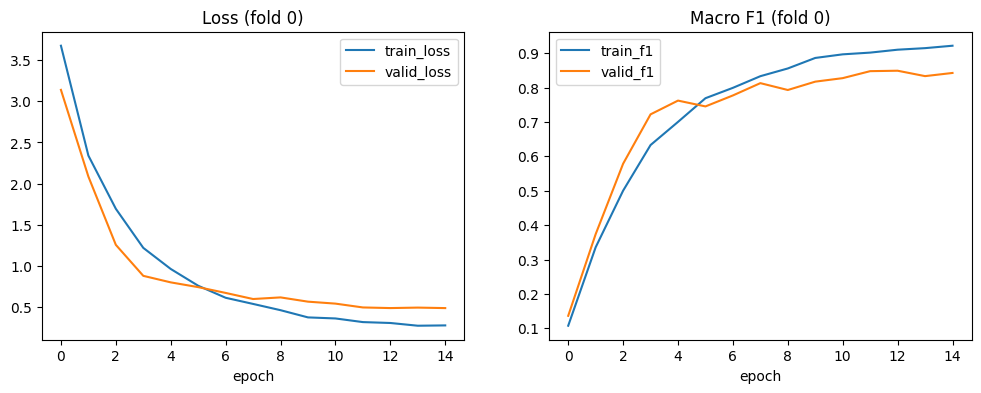

In [17]:
history = pd.read_csv(os.path.join(os.path.dirname(os.path.dirname(best_ckpts[0])), "metrics.csv"))
history = history.groupby("epoch").mean(numeric_only=True)

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
history[["train_loss", "valid_loss"]].plot(ax=axs[0], title="Loss (fold 0)")
history[["train_f1", "valid_f1"]].plot(ax=axs[1], title="Macro F1 (fold 0)")
plt.show()

<a id='Evaluation'></a>
## Evaluation and error analysis

In [18]:
def load_model(ckpt_path):
    model = SpecCNNClassifier(pretrained=False)
    state_dict = torch.load(ckpt_path, map_location="cpu")["state_dict"]
    model.load_state_dict({k.removeprefix("model."): v for k, v in state_dict.items()})
    return model.eval().to(DEVICE)


@torch.inference_mode()
def predict_logits(model, df):
    return torch.cat([model(x.to(DEVICE)).float().cpu() for x, _ in make_loader(df, train=False)])


oof_logits = torch.zeros(len(train_df), N_CLASSES)
test_logits = []
for fold_id, ckpt in enumerate(best_ckpts):
    model = load_model(ckpt)
    is_val = (train_df["fold"] == fold_id).to_numpy()
    oof_logits[is_val] = predict_logits(model, train_df[is_val])
    test_logits.append(predict_logits(model, test_df))

metrics = torchmetrics.MetricCollection({
    "accuracy": torchmetrics.Accuracy(task="multiclass", num_classes=N_CLASSES),
    "macro_f1": torchmetrics.F1Score(task="multiclass", num_classes=N_CLASSES, average="macro"),
})
oof_metrics = metrics(oof_logits.argmax(-1), torch.tensor(train_df["target"].values))
test_metrics = metrics(torch.stack(test_logits).softmax(-1).mean(0).argmax(-1), torch.tensor(test_df["target"].values))
pd.DataFrame({
    "OOF (5 folds)": {k: v.item() for k, v in oof_metrics.items()},
    "Test (5-fold ensemble)": {k: v.item() for k, v in test_metrics.items()},
}).round(3)

,OOF (5 folds),Test (5-fold ensemble)
accuracy,0.836,0.908
macro_f1,0.835,0.886


Where does the model make mistakes? The most frequently confused pairs often make sense acoustically.

In [19]:
oof_pred = oof_logits.argmax(-1).numpy()
errors = train_df.assign(pred=[class_idx2name[p] for p in oof_pred])[oof_pred != train_df["target"].values]

print(f"OOF errors: {len(errors)} / {len(train_df)}\n")
print("Most confused pairs (true -> predicted):")
errors.groupby(["category", "pred"]).size().sort_values(ascending=False).head(10)

OOF errors: 297 / 1816

Most confused pairs (true -> predicted):


category          pred           
door_wood_creaks  cat                7
washing_machine   engine             5
water_drops       clock_tick         5
keyboard_typing   mouse_click        4
hen               laughing           4
helicopter        washing_machine    4
rain              crackling_fire     4
wind              airplane           4
water_drops       mouse_click        4
train             sea_waves          3
dtype: int64

In [20]:
print("Worst classes by OOF recall:")
(1 - errors["category"].value_counts() / train_df["category"].value_counts()).sort_values().head(5).round(2)

Worst classes by OOF recall:


category
helicopter          0.55
wind                0.57
water_drops         0.61
door_wood_creaks    0.62
train               0.65
Name: count, dtype: float64

In [21]:
# Listen to a couple of mistakes
for _, row in errors.head(2).iterrows():
    print(f"true: {row['category']}  |  predicted: {row['pred']}")
    ipd.display(ipd.Audio(row["filepath"]))

true: thunderstorm  |  predicted: train


true: fireworks  |  predicted: thunderstorm


**Things to try** to improve the score: MixUp, longer training, a bigger backbone, pretrained *audio* models ([PANNs](https://arxiv.org/abs/1912.10211), [BEATs](https://arxiv.org/abs/2212.09058), [AST](https://arxiv.org/abs/2104.01778)).

<a id='Bridge'></a>
# From clip labels to label sequences

Look again at the CNN feature map: its shape is `(channels, frequency, time)`. The classifier **averages away** the time axis because one label is enough for the whole clip.

What if we keep the time axis and classify **every frame**?

* Sound event detection: "dog barking from 1.2s to 2.0s" - frame-level classification.
* **Speech recognition**: every frame gets a character... but we do not know which frame corresponds to which character. Transcripts have no timestamps.

So ASR is "classification over time" + a way to deal with the **unknown alignment**. There are two main answers:

1. **CTC**: an encoder classifies every frame, and a special loss sums over all possible alignments.
2. **Sequence-to-sequence**: a decoder generates the text token by token, attending to the audio (like a language model conditioned on audio).

<a id='Part2'></a>
# Part 2. Automatic Speech Recognition

![](images/intro_meme.jpg)

Automatic Speech Recognition (ASR) converts spoken language into text: voice assistants, call centers, subtitles, meeting transcription, dictation.

What makes it hard:
* **Vocabulary and context**: digit recognition is easy, open-domain conversations are not.
* **Speaker variability**: accents, dialects, spontaneous speech, overlaps.
* **Environment**: noise, reverberation, far-field microphones.
* **Text side**: punctuation, casing, numbers, names, code-switching (surzhyk!).

<a id='ASR-Data'></a>
## Task and data

Ukrainian speech: transcribed fragments of the "Toronto TV" YouTube channel. Credits for the data go to [Yurii Laba](https://www.linkedin.com/in/yura-laba/).

Download the data from [Google Drive](https://drive.google.com/file/d/1j9d91QqE7_WnOnmEmidtOG55tpmxQUeJ/view?usp=sharing) (~9GB) and unzip it into `../data/toronto`.

We only need the **test** split here (whole videos are held out, so no speaker/episode leakage).

In [22]:
TORONTO_ROOT = "../data/toronto/"
TEST_VIDEOS = [
    "toronto_27", "toronto_46", "toronto_42", "toronto_37", "toronto_89", "toronto_43", "toronto_157",
    "toronto_9", "toronto_156", "toronto_7", "toronto_123", "toronto_54", "toronto_67", "toronto_62",
    "toronto_81", "toronto_134", "toronto_148", "toronto_21", "toronto_135", "toronto_166", "toronto_58",
]

with jsonlines.open(os.path.join(TORONTO_ROOT, "labels.jsonl")) as reader:
    labels = next(iter(reader))  # one json object: {"dataset/<video>/<file>.wav": transcript}

asr_df = pd.DataFrame({"path": sorted(glob(os.path.join(TORONTO_ROOT, "toronto_*/*.wav")))})
asr_df["video"] = asr_df["path"].apply(lambda p: p.split("/")[-2])
asr_df["transcript"] = asr_df["path"].apply(lambda p: labels["dataset/" + "/".join(p.split("/")[-2:])])
asr_df = asr_df[asr_df["video"].isin(TEST_VIDEOS)].reset_index(drop=True)
asr_df["duration"] = asr_df["path"].apply(lambda p: sf.info(p).duration)

print(f"Test utterances: {len(asr_df)} | total audio: {asr_df['duration'].sum() / 3600:.1f} h")
asr_df.head()

Test utterances: 5542 | total audio: 9.2 h


,path,video,transcript,duration
0,../data/toronto/toronto_123/toronto_123_0.wav,toronto_123,Слава Ісу! Ви дивитесь програму «#@)₴?$0» . Я ...,6.67
1,../data/toronto/toronto_123/toronto_123_1.wav,toronto_123,Валарморгулісне! Україна за три тижні до вибор...,6.76
2,../data/toronto/toronto_123/toronto_123_10.wav,toronto_123,"стан людини, яка на виборчій дільниці отримала...",4.53
3,../data/toronto/toronto_123/toronto_123_100.wav,toronto_123,"Ну, а хто ж на верхівці цього чучундрологічног...",5.17
4,../data/toronto/toronto_123/toronto_123_101.wav,toronto_123,Саме тому ми і називаємо її «інкогніто». Чи не...,5.61


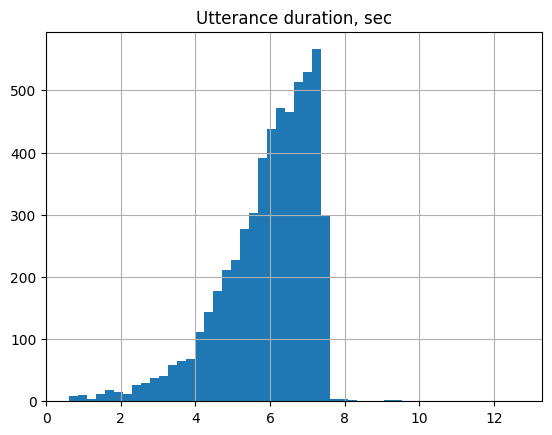

In [23]:
asr_df["duration"].hist(bins=50)
plt.title("Utterance duration, sec")
plt.show()

In [24]:
sample = asr_df[asr_df["path"].str.endswith("toronto_43/toronto_43_8.wav")].iloc[0]
ASR_SR = 16_000
sample_audio, _ = librosa.load(sample["path"], sr=ASR_SR)

print(sample["transcript"])
ipd.Audio(sample_audio, rate=ASR_SR)

Дивно, що цей мод зі зміною тіл написали не сестри Вачо́вські.


<a id='ASR-Metrics'></a>
## Metrics: WER and CER

**Word Error Rate**: the minimal number of word substitutions $S$, deletions $D$ and insertions $I$ needed to turn the hypothesis into the reference (Levenshtein distance over words), divided by the number of reference words $N$:

$$WER = \frac{S + D + I}{N}$$

**Character Error Rate (CER)** is the same over characters. CER is more forgiving to small spelling errors and is better for morphologically rich languages like Ukrainian.

Note: WER is not bounded by 1 - insertions can make it arbitrarily large.

In [25]:
def levenshtein(ref, hyp):
    """Edit distance between two sequences (strings or lists of words)."""
    prev = list(range(len(hyp) + 1))
    for i, r in enumerate(ref, start=1):
        cur = [i]
        for j, h in enumerate(hyp, start=1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (r != h)))  # deletion, insertion, substitution
        prev = cur
    return prev[-1]


def wer(ref, hyp):
    return levenshtein(ref.split(), hyp.split()) / len(ref.split())


def cer(ref, hyp):
    return levenshtein(ref, hyp) / len(ref)


ref = "дивно що цей мод зі зміною тіл написали не сестри вачовські"
for hyp in [ref, "дивно що цей мод зі зміною тіл написали несестри вачовські", "дивно дивно дивно дивно що"]:
    print(f"WER={wer(ref, hyp):.3f}  CER={cer(ref, hyp):.3f}  jiwer WER={jiwer.wer(ref, hyp):.3f}  | {hyp}")

WER=0.000  CER=0.000  jiwer WER=0.000  | дивно що цей мод зі зміною тіл написали не сестри вачовські
WER=0.182  CER=0.017  jiwer WER=0.182  | дивно що цей мод зі зміною тіл написали несестри вачовські
WER=0.909  CER=0.729  jiwer WER=0.909  | дивно дивно дивно дивно що


### Text normalization matters

References contain punctuation, capital letters and stress marks (`Вачо́вські`). A model trained on lowercase text without punctuation would get a terrible WER on raw references - not because it misheard anything.

**Always normalize both reference and hypothesis the same way before computing metrics**, and report which normalization was used.

In [26]:
def normalize_text(text):
    text = unicodedata.normalize("NFD", str(text)).replace("́", "")  # drop stress marks
    text = unicodedata.normalize("NFC", text).lower()
    text = re.sub(r"[’ʼ`‘]", "'", text)  # unify apostrophes
    text = re.sub(r"[^\w\s']", " ", text)  # drop punctuation
    return " ".join(text.split())


print("raw:       ", sample["transcript"])
print("normalized:", normalize_text(sample["transcript"]))

asr_df["reference"] = asr_df["transcript"].apply(normalize_text)
asr_df = asr_df[asr_df["reference"].str.len() > 0].reset_index(drop=True)

raw:        Дивно, що цей мод зі зміною тіл написали не сестри Вачо́вські.
normalized: дивно що цей мод зі зміною тіл написали не сестри вачовські


<a id='ASR-CTC'></a>
## CTC approach

![](images/ctc_meme.jpg)

**Encoder-only model**: audio goes in, every frame (20-40ms) gets a probability distribution over characters (+ a special *blank* symbol). Typical example: [wav2vec 2.0](https://arxiv.org/abs/2006.11477).

![Wav2Vec description](images/wave2vec2_shorten.png)

1. **Feature encoder** (CNN over raw waveform or a mel spectrogram) - one vector per frame.
2. **Transformer** - contextualizes the frames.
3. **Pre-training** in a self-supervised way on lots of *unlabeled* audio (mask frames and predict them), then **fine-tuning** with the CTC loss on a relatively small labeled set.

We will use [`Yehor/w2v-bert-2.0-uk-v2.1`](https://huggingface.co/Yehor/w2v-bert-2.0-uk-v2.1): Meta's [w2v-BERT 2.0](https://huggingface.co/facebook/w2v-bert-2.0) encoder (pre-trained on 4.5M hours) fine-tuned for Ukrainian with CTC.

In [27]:
from transformers import AutoModelForCTC, Wav2Vec2BertProcessor

ctc_model_name = "Yehor/w2v-bert-2.0-uk-v2.1"
ctc_model = AutoModelForCTC.from_pretrained(ctc_model_name, dtype=torch.float16).to(DEVICE).eval()
ctc_processor = Wav2Vec2BertProcessor.from_pretrained(ctc_model_name)

print(f"Parameters: {sum(p.numel() for p in ctc_model.parameters()) / 1e6:.0f}M")
print("Vocabulary:", "".join(ctc_processor.tokenizer.get_vocab()))

Parameters: 606M
Vocabulary: '<pad><unk>|абвгдежзийклмнопрстуфхцчшщьюяєіїґ<s></s>


In [28]:
inputs = ctc_processor([sample_audio], sampling_rate=ASR_SR, return_tensors="pt").to(DEVICE)
with torch.inference_mode():
    logits = ctc_model(inputs.input_features.half()).logits.float()

print(f"Audio: {len(sample_audio) / ASR_SR:.2f} sec -> logits: {tuple(logits.shape)}  (frames x vocabulary)")
print(f"One frame = {len(sample_audio) / ASR_SR / logits.shape[1] * 1000:.0f} ms")

Audio: 3.20 sec -> logits: (1, 80, 39)  (frames x vocabulary)
One frame = 40 ms


The output is a **classification of every frame**. Exactly like in Part 1, but with a time axis. Let's look at the most likely symbol per frame:

In [29]:
frame_ids = logits.argmax(-1)[0]
frame_tokens = ctc_processor.tokenizer.convert_ids_to_tokens(frame_ids.tolist())
print(" ".join(frame_tokens).replace("<pad>", "_"))

_ _ _ _ д _ и в н о | | щ о | | ц е й | | м о д _ | з і | | з м і н о _ ю | т і _ л | | н а п и с а л _ и | _ н е _ с е _ с с т р и и _ в а ч о _ в с ь к і _ _


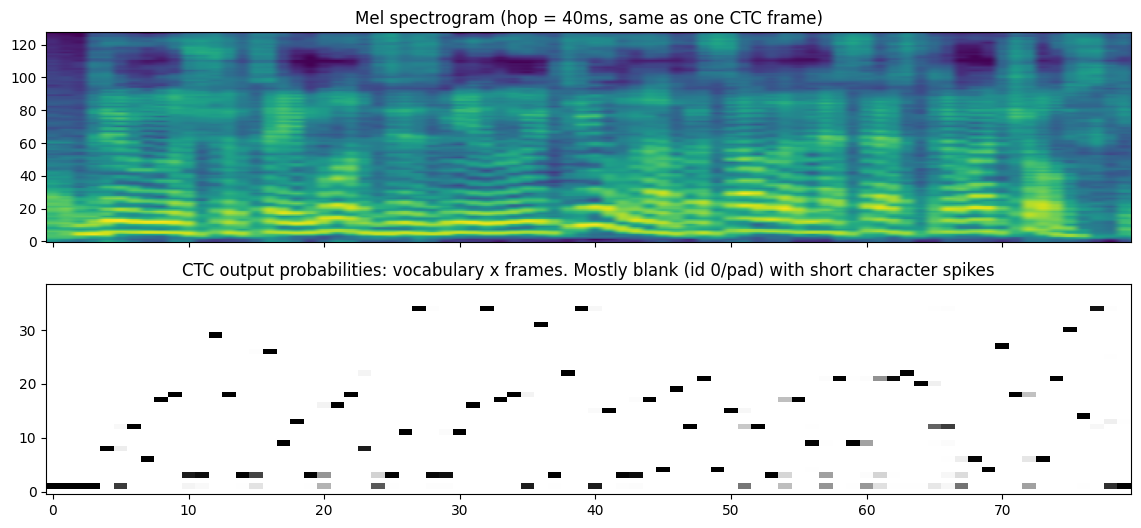

In [30]:
fig, axs = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
axs[0].imshow(librosa.power_to_db(librosa.feature.melspectrogram(y=sample_audio, sr=ASR_SR, hop_length=640)), origin="lower", aspect="auto")
axs[0].set_title("Mel spectrogram (hop = 40ms, same as one CTC frame)")
axs[1].imshow(logits[0].softmax(-1).T.cpu(), origin="lower", aspect="auto", interpolation="nearest", cmap="Greys")
axs[1].set_title("CTC output probabilities: vocabulary x frames. Mostly blank (id 0/pad) with short character spikes")
plt.show()

### How do we get text from frame labels?

Naive idea: merge repeated characters. It fails on double letters and has no way to express silence:

![](images/basic_decoding.png)

**CTC** ([Graves et al., 2006](https://www.cs.toronto.edu/~graves/icml_2006.pdf)) adds a **blank** symbol `⌴`. The collapsing function $B$:
1. merge consecutive repeated symbols;
2. remove blanks.

A blank between two `n` keeps them as two letters: `n n ⌴ n` -> `nn`.

![](images/ctc_collapsing_function.png)

In [ ]:
def ctc_greedy_decode(frame_ids, blank_id, word_delimiter_id):
    """Best path decoding: argmax per frame -> merge repeats -> drop blanks."""
    collapsed = [i for k, i in enumerate(frame_ids) if k == 0 or i != frame_ids[k - 1]]
    chars = [ctc_processor.tokenizer.convert_ids_to_tokens(i) for i in collapsed if i != blank_id]
    return " ".join("".join(chars).replace(ctc_processor.tokenizer.convert_ids_to_tokens(word_delimiter_id), " ").split())


tok = ctc_processor.tokenizer
my_decoding = ctc_greedy_decode(frame_ids.tolist(), blank_id=tok.pad_token_id, word_delimiter_id=tok.word_delimiter_token_id)
hf_decoding = ctc_processor.batch_decode(frame_ids[None])[0]

print("our decoding:", my_decoding)
print("HF decoding: ", hf_decoding)
print("reference:   ", normalize_text(sample["transcript"]))

### CTC loss: sum over all alignments

Many alignments collapse into the same text:

![](images/other_alignments.png)

CTC assumes that frames are conditionally independent given the audio, and defines the probability of the text $Y$ as the **sum over all alignments** $A$ that collapse to it:

$$P_{CTC}(Y \mid X) = \sum_{A \in B^{-1}(Y)} \prod_{t=1}^{T} p(a_t \mid X), \qquad \mathcal{L}_{CTC} = -\log P_{CTC}(Y \mid X)$$

The number of alignments grows exponentially, but the sum is computed with dynamic programming (forward-backward algorithm) in $O(T \cdot |Y|)$. **No frame-level labels needed** - only the transcript.

Toy example: 2 frames, vocabulary `{⌴, a}`.

![](images/all_paths_to_a.png)

In [31]:
# frame 1: P(⌴)=0.8, P(a)=0.2 ; frame 2: P(⌴)=0.6, P(a)=0.4
probs = torch.tensor([[0.8, 0.2], [0.6, 0.4]])
log_probs = probs.log().unsqueeze(1)  # (T, batch, vocab)

for text, target in [("a", [1]), ("'' (empty)", [])]:
    loss = F.ctc_loss(log_probs, torch.tensor([target], dtype=torch.long), input_lengths=torch.tensor([2]), target_lengths=torch.tensor([len(target)]), blank=0, reduction="sum")
    print(f"P({text}) = exp(-CTC loss) = {loss.neg().exp().item():.2f}")

print("\nP(a) by hand: aa + a⌴ + ⌴a =", 0.2 * 0.4 + 0.2 * 0.6 + 0.8 * 0.4)

P(a) = exp(-CTC loss) = 0.52
P('' (empty)) = exp(-CTC loss) = 0.48

P(a) by hand: aa + a⌴ + ⌴a = 0.52


The best path is `⌴⌴` (0.8 * 0.6 = 0.48 -> empty text), but the most probable **text** is `a` (0.52). Greedy decoding can be wrong, therefore in practice we use **beam search**, often with an external n-gram language model ([pyctcdecode](https://github.com/kensho-technologies/pyctcdecode), [torchaudio CTC decoder](https://pytorch.org/audio/stable/tutorials/asr_inference_with_ctc_decoder_tutorial.html)).

Let's evaluate the CTC model on the whole test set. Sorting utterances by duration minimizes padding in a batch.

In [32]:
def batched_by_duration(df, batch_size):
    order = df["duration"].sort_values().index.to_numpy()
    return [order[i:i + batch_size] for i in range(0, len(order), batch_size)]


@torch.inference_mode()
def transcribe_ctc(df, batch_size=32):
    hyps = pd.Series(index=df.index, dtype=object)
    for idx in tqdm(batched_by_duration(df, batch_size)):
        audios = [librosa.load(p, sr=ASR_SR)[0] for p in df.loc[idx, "path"]]
        inputs = ctc_processor(audios, sampling_rate=ASR_SR, return_tensors="pt", padding=True).to(DEVICE)
        logits = ctc_model(inputs.input_features.half(), attention_mask=inputs.attention_mask).logits
        hyps[idx] = ctc_processor.batch_decode(logits.argmax(-1))
    return hyps.to_list()


start = time.time()
asr_df["ctc_hyp"] = transcribe_ctc(asr_df)
ctc_time = time.time() - start
print(f"Done in {ctc_time:.0f} sec")

  0%|          | 0/173 [00:00<?, ?it/s]

Done in 171 sec


<a id='ASR-Seq2Seq'></a>
## Sequence-to-sequence approach: Whisper

Instead of classifying frames, an **encoder-decoder Transformer** generates the transcript token by token: the decoder is a language model conditioned on the audio through cross-attention. No conditional independence assumption and no alignment problem - the attention learns where to look.

![Image Title](images/whisper_architecture.png)

[Whisper](https://arxiv.org/abs/2212.04356) (OpenAI):
* **Data**: 680k hours (v3: 5M hours) of weakly supervised audio-transcript pairs from the internet. Heavy filtering: removing machine-generated transcripts (e.g. all upper/lower case), language mismatch, low-quality sources.
* **Model**: an off-the-shelf encoder-decoder Transformer on 80 (v3: 128) channel log-mel spectrograms, 30 sec windows. Byte-level BPE tokens, so it predicts punctuation and casing.
* **Multitask format**: special tokens select the language and task - transcription, translation to English, language identification, voice activity detection, timestamps.

![Image Title](images/whisper_multitask.png)

In [33]:
from transformers import AutoProcessor, WhisperForConditionalGeneration

whisper_model_name = "openai/whisper-large-v3"
whisper_model = WhisperForConditionalGeneration.from_pretrained(whisper_model_name, dtype=torch.float16, attn_implementation="sdpa").to(DEVICE).eval()
whisper_processor = AutoProcessor.from_pretrained(whisper_model_name)

print(f"Parameters: {sum(p.numel() for p in whisper_model.parameters()) / 1e6:.0f}M")

Parameters: 1543M


In [34]:
@torch.inference_mode()
def whisper_transcribe(audios, **generate_kwargs):
    inputs = whisper_processor(audios, sampling_rate=ASR_SR, return_tensors="pt", return_attention_mask=True).to(DEVICE)
    generated_ids = whisper_model.generate(inputs.input_features.half(), attention_mask=inputs.attention_mask, **generate_kwargs)
    return whisper_processor.batch_decode(generated_ids, skip_special_tokens=True)


print("reference:   ", sample["transcript"])
print("transcribe:  ", whisper_transcribe([sample_audio], language="uk", task="transcribe")[0])
print("translate:   ", whisper_transcribe([sample_audio], language="uk", task="translate")[0])

reference:    Дивно, що цей мод зі зміною тіл написали не сестри Вачо́вські.
transcribe:    Дивно, що цей мод зі зміною тіл написали не сестри Вачовські.
translate:     It's strange that this mod with a body change was written by not Sister Vachovsky.


Whisper can also predict **timestamps** - they are just special tokens in the vocabulary:

In [35]:
inputs = whisper_processor([sample_audio], sampling_rate=ASR_SR, return_tensors="pt", return_attention_mask=True).to(DEVICE)
with torch.inference_mode():
    generated_ids = whisper_model.generate(inputs.input_features.half(), attention_mask=inputs.attention_mask, language="uk", task="transcribe", return_timestamps=True)
print(whisper_processor.batch_decode(generated_ids, decode_with_timestamps=True)[0])

<|0.00|> Дивно, що цей мод зі зміною тіл написали не сестри Вачовські.<|3.20|>


In [36]:
def transcribe_whisper(df, batch_size=32):
    hyps = pd.Series(index=df.index, dtype=object)
    for idx in tqdm(batched_by_duration(df, batch_size)):
        audios = [librosa.load(p, sr=ASR_SR)[0] for p in df.loc[idx, "path"]]
        hyps[idx] = whisper_transcribe(audios, language="uk", task="transcribe")
    return hyps.to_list()


start = time.time()
asr_df["whisper_hyp"] = transcribe_whisper(asr_df)
whisper_time = time.time() - start
print(f"Done in {whisper_time:.0f} sec")

  0%|          | 0/173 [00:00<?, ?it/s]

Done in 885 sec


<a id='ASR-Comparison'></a>
## CTC vs Seq2Seq comparison

We report **corpus-level** WER/CER: total number of errors divided by the total number of reference words / characters (`jiwer` does it for lists).

In [37]:
refs = asr_df["reference"].to_list()
total_audio_sec = asr_df["duration"].sum()

results = pd.DataFrame({
    name: {
        "WER raw text": jiwer.wer(asr_df["transcript"].to_list(), asr_df[col].to_list()),
        "WER normalized": jiwer.wer(refs, asr_df[col].apply(normalize_text).to_list()),
        "CER normalized": jiwer.cer(refs, asr_df[col].apply(normalize_text).to_list()),
        "Params, M": sum(p.numel() for p in model.parameters()) / 1e6,
        "Real-time factor": elapsed / total_audio_sec,
    }
    for name, col, model, elapsed in [
        ("w2v-BERT 2.0 + CTC", "ctc_hyp", ctc_model, ctc_time),
        ("Whisper large-v3", "whisper_hyp", whisper_model, whisper_time),
    ]
}).T
results.round(3)

,WER raw text,WER normalized,CER normalized,"Params, M",Real-time factor
w2v-BERT 2.0 + CTC,0.556,0.329,0.157,605.718,0.005
Whisper large-v3,0.275,0.174,0.124,1543.491,0.027


Notes:
* *WER raw text* is much worse for the CTC model mostly because it does not produce punctuation and capital letters. Normalization shrinks the gap.
* *Real-time factor* = processing time / audio duration (includes audio loading). Lower is faster.

Let's look at the examples where the two models disagree the most.

In [38]:
asr_df["ctc_wer"] = [jiwer.wer(r, normalize_text(h)) if normalize_text(h) else 1.0 for r, h in zip(refs, asr_df["ctc_hyp"])]
asr_df["whisper_wer"] = [jiwer.wer(r, normalize_text(h)) if normalize_text(h) else 1.0 for r, h in zip(refs, asr_df["whisper_hyp"])]

def short(text, max_len=200):
    return text if len(text) <= max_len else text[:max_len] + " ..."


for title, rows in [
    ("Whisper is much better", asr_df.assign(d=asr_df["ctc_wer"] - asr_df["whisper_wer"]).nlargest(3, "d")),
    ("CTC is much better", asr_df.assign(d=asr_df["whisper_wer"] - asr_df["ctc_wer"]).nlargest(3, "d")),
]:
    print(f"===== {title} =====")
    for _, row in rows.iterrows():
        print(f"REF:     {row['reference']}\nCTC:     {short(row['ctc_hyp'])}\nWHISPER: {short(row['whisper_hyp'])}\n")

===== Whisper is much better =====
REF:     слугозеленське
CTC:     фіксую це кругій робнішслуга зеленське
WHISPER:  Слуго Зеленське!

REF:     та скубуться за щит капітана америки
CTC:     купиць сміт зруйнований у останніх месник та скубується за щит капітана америки
WHISPER:  Та скубуться за щит капітана Америки.

REF:     а щур один
CTC:     ащуродин
WHISPER:  А Щур – один.

===== CTC is much better =====
REF:     буй буй буй бу бу буй буй
CTC:     
WHISPER:  Ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-ой-о ...

REF:     навіть такі про які вам не хотілося б нічого знати пооо пееее попереду порошенко
CTC:     навіть ті про які вам не хотілося б нічого знати
WHISPER:  Навіть ті, про які вам не хотілося б нічого знати. Попе-е-е-е-е-е-е-е-е-е-е-е-е-е-е-е-е-е-е-е-е-е-е-е-е-е-е-е-е-е-е-е-е-е-е-е-е-е-е-е-е-е-е-е-е-е-е-е-е-е-е-е-е-е-е-е-е-е

Typical failure modes:
* **CTC**: phonetically plausible but misspelled words, merged/split words (`несестривачовські`) - every frame is decided locally, there is no language model inside.
* **Whisper**: fluent but *hallucinated* text, endless repetition loops (see above; mitigations: `no_repeat_ngram_size`, compression-ratio check with temperature fallback, VAD), dropping a part of the utterance, writing numbers as digits, "correcting" surzhyk into literary Ukrainian.

| | CTC (encoder-only) | Seq2Seq (encoder-decoder) |
|---|---|---|
| Output | frame-level classification | autoregressive generation |
| Alignment | monotonic, summed over by the loss | learned by cross-attention |
| Language modeling | none inside (add an n-gram LM in beam search) | built into the decoder |
| Speed | one forward pass, very fast | token-by-token decoding |
| Streaming | natural | hard (30 sec windows) |
| Typical errors | spelling | hallucinations |
| Extra tasks | timestamps from frames | translation, language ID, punctuation, timestamps |

Modern systems often combine both: hybrid CTC/attention training, Transducers (RNN-T, TDT in NVIDIA [Parakeet](https://huggingface.co/nvidia/parakeet-tdt-0.6b-v3)), LLM decoders on top of speech encoders.

<a id='Takeaways'></a>
# Takeaways

1. **Validation first**: find the hidden groups (source recording, speaker, video) and split by them. Otherwise every number below is a lie.
2. A clip classifier is a **feature extractor + encoder + pooling + head**. Spectrograms + ImageNet CNNs are a strong, cheap baseline; augmentations (waveform, SpecAugment, MixUp) matter a lot on small data.
3. ASR is **classification over time with unknown alignment**. CTC solves it by summing over alignments; seq2seq models generate the text with an autoregressive decoder.
4. **Metrics are defined by normalization.** The same predictions can have WER 0.7 or 0.2 depending on punctuation and casing.
5. Large pre-trained models (w2v-BERT, Whisper) are the default starting point; fine-tuning on your domain is the next step.

## Homework ideas

* ESC-50: add MixUp and GeM pooling, try a pretrained audio backbone. How much does the test F1 improve?
* ASR: fine-tune [w2v-BERT 2.0](https://huggingface.co/blog/fine-tune-w2v2-bert) or [Whisper](https://huggingface.co/blog/fine-tune-whisper) on the train videos of the Toronto dataset and compare with the numbers above on the same test videos.
* ASR: add beam search with an n-gram LM to the CTC model ([pyctcdecode](https://github.com/kensho-technologies/pyctcdecode)) and measure the WER change.